# System Validation Notebook
Digital Restoration of Indian Folk Paintings. Covers data augmentation and patch-conversion statistics, synthetic damage samples, segmentation and colour loss curves, and a comparison on **real** labelled tiles (classical detector vs U-Net, with per-class metrics).

No Mandawa (test) data is read here. Displayed images are limited to Kalighat paintings from the Kaggle "Indian paintings" dataset; all numbers use the full training/validation sets.

In [1]:
import sys, json
from pathlib import Path
ROOT = next(d for d in [Path.cwd(), *Path.cwd().parents] if (d / 'restoration').is_dir())  # project root
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2, torch
from restoration.utils import list_images, imread_rgb, imread_any, resize_max_side
from restoration.dataset import load_real_pairs, random_crop
from restoration.synth_damage import SynthConfig, synthesize, synthetic_fade, load_damage_bank
from restoration.preprocess import classical_crack_mask, clahe_lab

# ---- configuration ----
CKPT_DIR  = ROOT / 'checkpoints'
CLEAN_DIR = ROOT / 'data/clean'
REAL_DIR  = ROOT / 'data/real_labeled'
BANK_DIR  = ROOT / 'data/damage_bank'
TILE, OVERLAP, MAX_SIDE = 384, 96, 3000

def is_shown(p):  # only Kalighat paintings are displayed
    return 'kalighat' in p.name and 'hf_' not in p.name

## 1. Dataset & patch-conversion rates
How many overlapping training patches each painting yields at the chosen tile size (the proposal's *sub-tile extraction* step), plus random-scale cropping which makes the effective set unlimited.

In [2]:
def n_patches(h, w, tile=TILE, overlap=OVERLAP):
    s = tile - overlap
    return max(1, (h - overlap) // s) * max(1, (w - overlap) // s)
rows = []
for p in list_images(CLEAN_DIR):
    im = imread_rgb(p); h, w = resize_max_side(im, MAX_SIDE)[0].shape[:2]
    rows.append({'image': p.name, 'size': f'{w}x{h}', 'patches_256': n_patches(h, w, 256, 64), f'patches_{TILE}': n_patches(h, w)})
stats = pd.DataFrame(rows)
real = load_real_pairs(REAL_DIR); bank = load_damage_bank(BANK_DIR)
print(f'clean paintings: {len(stats)} -> {stats.get(f"patches_{TILE}", pd.Series(dtype=int)).sum()} patches @{TILE}px '
      f'(x{stats.get(f"patches_{TILE}", pd.Series([0])).mean():.0f} per painting); real labelled tiles: {len(real)}; damage-bank cut-outs: {len(bank)}')
stats

clean paintings: 936 -> 8613 patches @384px (x9 per painting); real labelled tiles: 132; damage-bank cut-outs: 2501


,image,size,patches_256,patches_384
0,0000_gond.png,471x625,4,1
1,0001_gond.png,1200x900,20,6
2,0002_gond.png,1222x1500,42,12
3,0003_gond.png,674x933,12,4
4,0004_gond.png,1008x1200,20,9
...,...,...,...,...
931,1199_fresco_shekhawati.png,1280x853,24,8
932,1200_fresco_shekhawati.png,1280x853,24,8
933,1201_fresco_shekhawati.png,1280x960,24,12
934,1202_fresco_shekhawati.png,1280x772,18,8


In [3]:
if real:
    fr = []
    for ip, mp in real:
        m = imread_any(mp, cv2.IMREAD_GRAYSCALE)
        fr.append({'tile': ip.name, 'damage_%': 100*(m>0).mean(), 'crack_%': 100*(m==1).mean(), 'loss_%': 100*(m==2).mean(), 'stain_%': 100*(m==3).mean(), 'unknown_%': 100*(m==255).mean()})
    fr = pd.DataFrame(fr); display(fr.describe().round(2))
    print('Class imbalance: damage covers on average %.1f%% of pixels -> why Dice+Focal loss is used.' % fr['damage_%'].mean())

,damage_%,crack_%,loss_%,stain_%,unknown_%
count,132.00,132.00,132.00,132.00,132.00
mean,14.31,0.56,9.45,3.16,1.15
std,19.54,1.86,17.00,6.71,7.44
min,0.00,0.00,0.00,0.00,0.00
25%,0.83,0.00,0.00,0.00,0.00
50%,5.53,0.00,0.69,0.59,0.00
75%,18.70,0.20,10.10,3.23,0.00
max,87.20,16.37,80.70,48.12,67.77


Class imbalance: damage covers on average 14.3% of pixels -> why Dice+Focal loss is used.


## 2. Synthetic degradation samples
Columns: clean | synthetic damage | labels (red crack, blue loss, yellow stain) | synthetic fading.

0269_kalighat.png
0269_kalighat.png


0170_kalighat.png


0189_kalighat.png


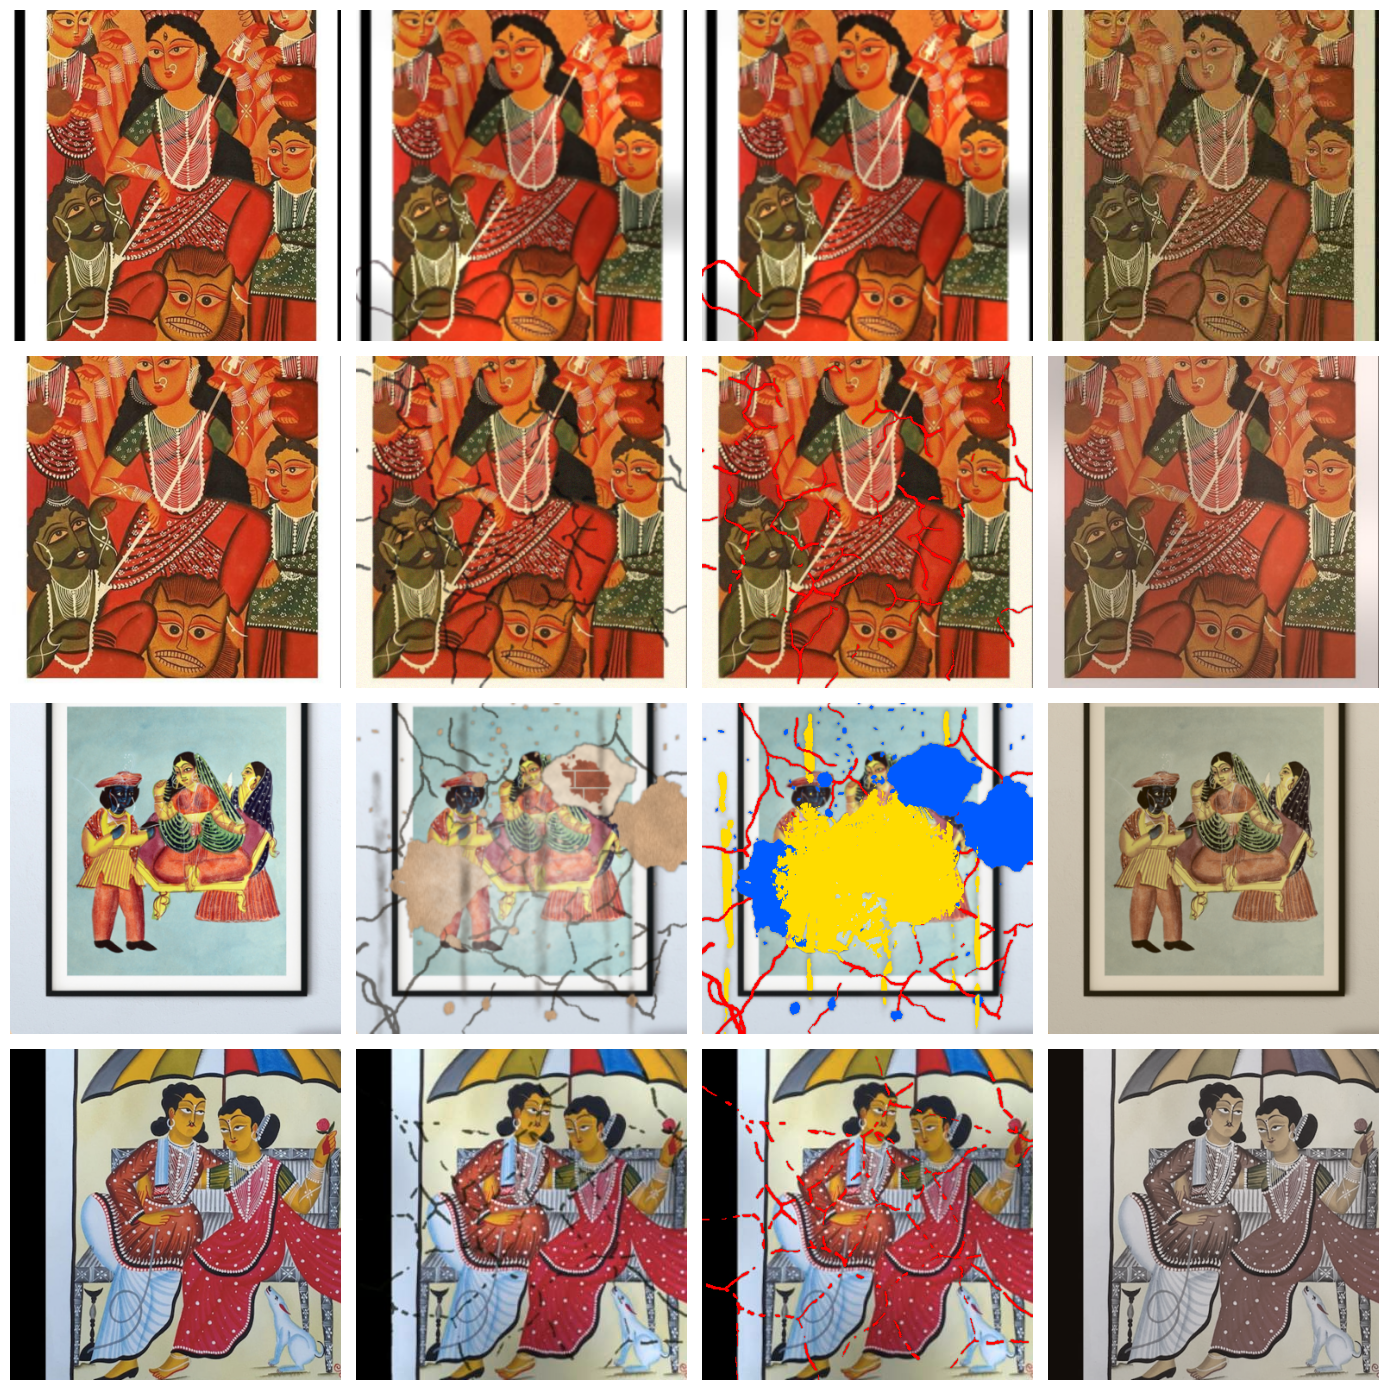

In [4]:
rng = np.random.default_rng(0); paths = [p for p in list_images(CLEAN_DIR) if is_shown(p)]
cfg = SynthConfig(p_clean=0.0)  # purely synthetic (no damage-bank cut-outs) for display
fig, ax = plt.subplots(4, 4, figsize=(14, 14))
for r in range(4):
    p = paths[rng.integers(len(paths))]; print(p.name)
    c = random_crop(imread_rgb(p), TILE, rng)
    d, lab = synthesize(c, rng, cfg); ov = d.copy()
    for k, col in enumerate([(255,0,0),(0,90,255),(255,220,0)]):
        ov[lab[...,k]>0] = col
    for j, im in enumerate([c, d, ov, synthetic_fade(c, rng)]):
        ax[r, j].imshow(im); ax[r, j].axis('off')
plt.tight_layout()

## 3. Segmentation training curves
**Real F1** is what matters; a large gap between synthetic and real F1 indicates a synthetic-to-real domain gap.

,epoch,train_loss,synth_f1,synth_iou,synth_thr,real_f1,real_iou,real_thr,lr,time_s
31,31,0.744704,0.826813,0.704758,0.6,0.531575,0.362004,0.5,0.000035,87.787889
32,32,0.743664,0.830864,0.710665,0.6,0.532642,0.362994,0.5,0.000027,87.892436
33,33,0.725971,0.831940,0.712241,0.6,0.521777,0.352976,0.5,0.000020,89.116953
34,34,0.729508,0.830151,0.709623,0.6,0.525798,0.356666,0.5,0.000014,86.578460
35,35,0.724621,0.832991,0.713783,0.6,0.533458,0.363752,0.5,0.000009,88.446854


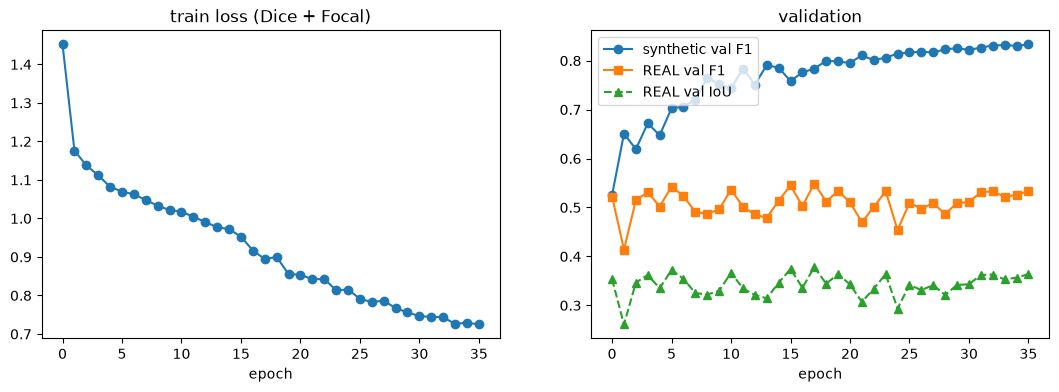

In [5]:
log = CKPT_DIR / 'seg_log.csv'
if log.exists():
    df = pd.read_csv(log)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(df.epoch, df.train_loss, 'o-'); ax[0].set_title('train loss (Dice + Focal)'); ax[0].set_xlabel('epoch')
    ax[1].plot(df.epoch, df.synth_f1, 'o-', label='synthetic val F1')
    if df.real_f1.notna().any(): ax[1].plot(df.epoch, df.real_f1, 's-', label='REAL val F1')
    ax[1].plot(df.epoch, df.real_iou, '^--', label='REAL val IoU'); ax[1].legend(); ax[1].set_title('validation'); ax[1].set_xlabel('epoch')
    display(df.tail())
else:
    print('No seg_log.csv yet - run scripts/train_seg.py')

## 4. Real-tile evaluation: classical baseline vs U-Net (per class)
36 validation tiles from 27 paintings never used for training. They were also used to pick the checkpoint and threshold, so the score is slightly optimistic. Scoring here is raw probability > threshold, so it differs slightly from the 0.55 logged during training.

The classical baseline only detects thin cracks, while most labelled damage is loss, so its low score partly reflects scope. Per-class scores use the same threshold and only tiles with typed labels; they are much weaker for cracks and stains than for damage / no damage.

,precision,recall,F1,IoU
classical (any),0.064,0.004,0.007,0.004
unet (any),0.493,0.584,0.535,0.365
unet crack,0.337,0.020,0.037,0.019
unet loss,0.587,0.553,0.569,0.398
unet stain,0.113,0.013,0.023,0.012


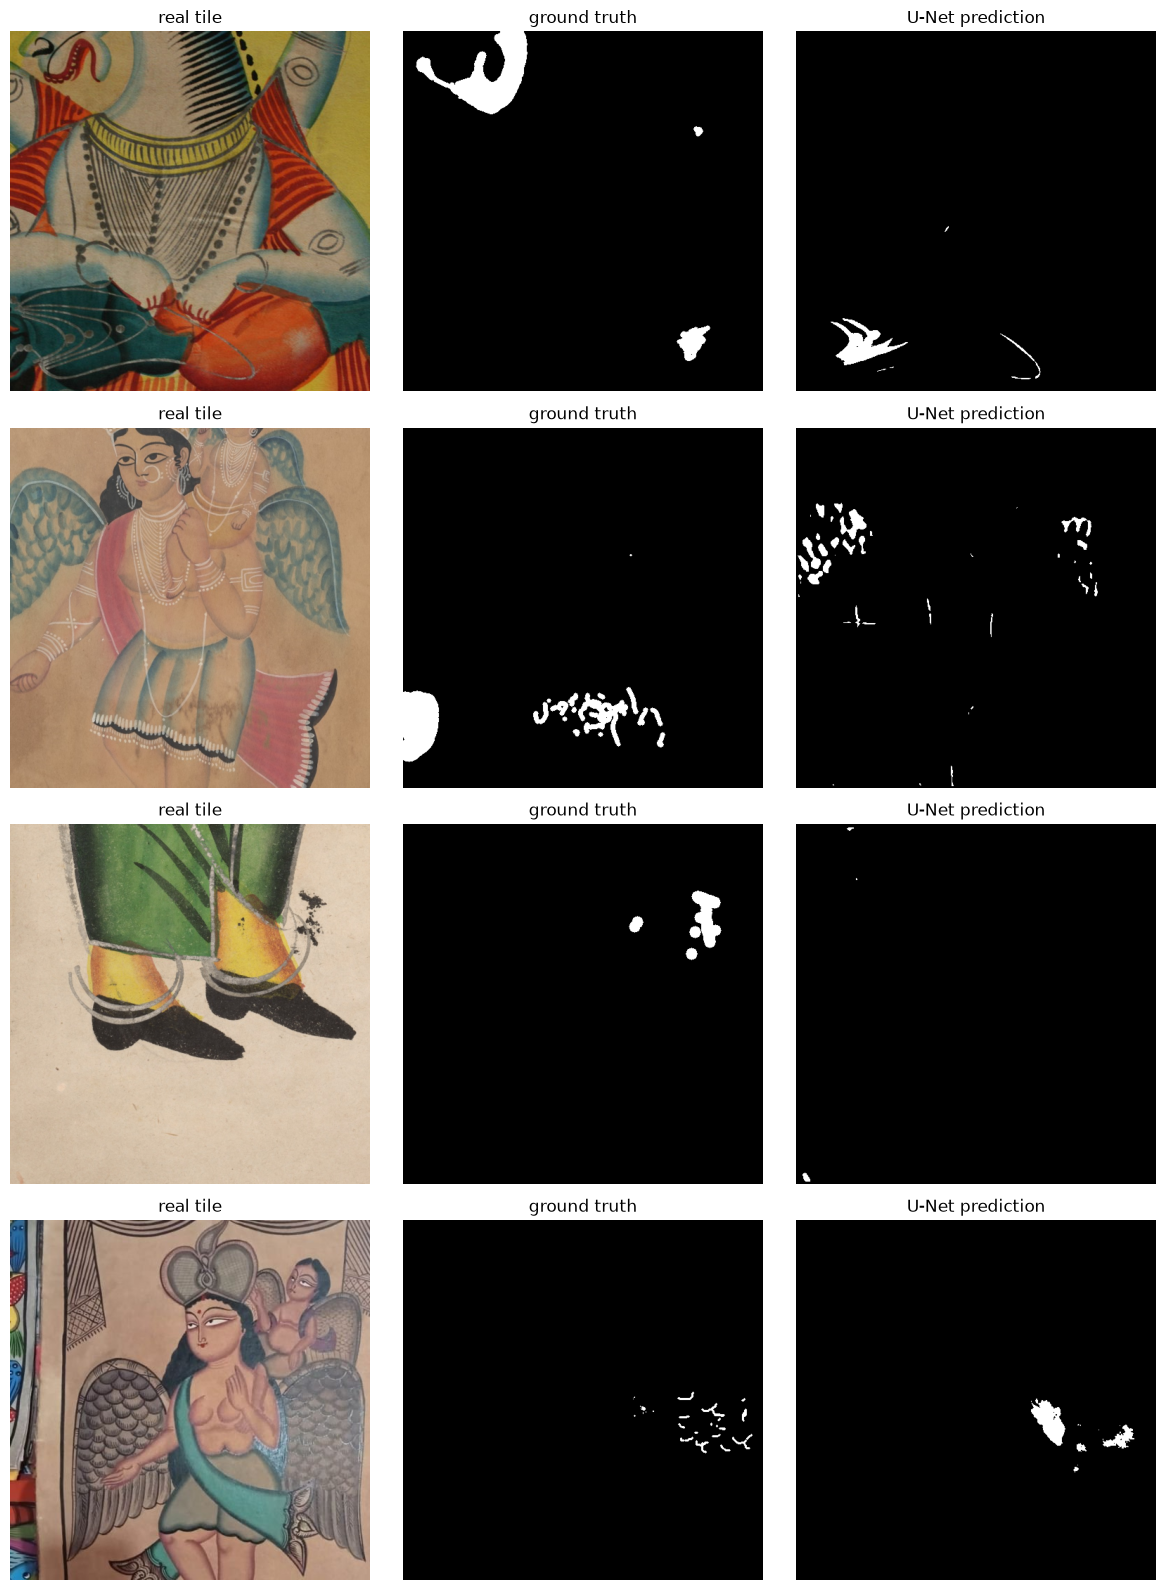

In [6]:
from restoration.dataset import split_paths
from restoration.segmentation import load_seg_model, predict_probs, CHANNELS
def prf(pred, gt):
    tp = (pred & gt).sum(); fp = (pred & ~gt).sum(); fn = (~pred & gt).sum()
    return tp, fp, fn
def summarize(c):
    tp, fp, fn = c
    return {'precision': tp/max(1,tp+fp), 'recall': tp/max(1,tp+fn), 'F1': 2*tp/max(1,2*tp+fp+fn), 'IoU': tp/max(1,tp+fp+fn)}
ck_path = CKPT_DIR / 'seg_best.pt'
_, val_pairs = split_paths(real, 0.3, seed=0)   # same split as train_seg.py
if val_pairs and ck_path.exists():
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model, ck = load_seg_model(ck_path, dev); thr = ck['threshold']
    acc = {k: np.zeros(3) for k in ['classical (any)', 'unet (any)', 'unet crack', 'unet loss', 'unet stain']}
    examples = []
    for ip, mp in val_pairs:
        img, m = imread_rgb(ip), imread_any(mp, cv2.IMREAD_GRAYSCALE)
        gt = m > 0
        acc['classical (any)'] += prf(classical_crack_mask(img) > 0, gt)
        probs, _ = predict_probs(model, img, dev, ck.get('use_clahe', True))
        acc['unet (any)'] += prf(probs[..., 0] > thr, gt)
        for ci, name in enumerate(['crack', 'loss', 'stain'], 1):
            if not (m == 255).any():  # per-class only on tiles whose damage types were labelled
                acc[f'unet {name}'] += prf(probs[..., ci] > thr, m == ci)
        if is_shown(ip) and gt.any():
            examples.append((ip.name.split('_y')[0], gt.mean(), img, gt, probs[..., 0] > thr))
    acc = {k: v for k, v in acc.items() if v[0] + v[2] > 0}  # drop classes with no labelled pixels
    display(pd.DataFrame({k: summarize(v) for k, v in acc.items()}).T.round(3))
    best = {}  # one tile per painting: the one with the most labelled damage (not chosen by score)
    for e in examples:
        if e[0] not in best or e[1] > best[e[0]][1]: best[e[0]] = e
    examples = [e[2:] for e in sorted(best.values(), key=lambda e: -e[1])]
    n = min(4, len(examples)); fig, ax = plt.subplots(n, 3, figsize=(12, 4*n), squeeze=False)
    for i, (img, gt, pr) in enumerate(examples[:n]):
        for j, (im, t) in enumerate([(img, 'real tile'), (gt, 'ground truth'), (pr, 'U-Net prediction')]):
            ax[i, j].imshow(im, cmap='gray'); ax[i, j].set_title(t); ax[i, j].axis('off')
    plt.tight_layout()
else:
    print('Need real labelled tiles (data/real_labeled) and checkpoints/seg_best.pt')

### Validation score by painting type
The pooled score above is dominated by frescoes, which hold nearly all the labelled damage pixels. Same model, threshold and scoring as above. Paper/cloth has few tiles with small, sparse damage, so its score is a rough figure.

In [7]:
if val_pairs and ck_path.exists():
    by_type = {'Frescoes / wall paintings': np.zeros(4), 'Paper and cloth': np.zeros(4), 'All': np.zeros(4)}  # tp, fp, fn, tiles
    for ip, mp in val_pairs:
        gt = imread_any(mp, cv2.IMREAD_GRAYSCALE) > 0
        probs, _ = predict_probs(model, imread_rgb(ip), dev, ck.get('use_clahe', True))
        c = np.array([*prf(probs[..., 0] > thr, gt), 1], float)
        by_type['Frescoes / wall paintings' if 'fresco' in ip.name else 'Paper and cloth'] += c
        by_type['All'] += c
    total = by_type['All'][0] + by_type['All'][2]
    tab = pd.DataFrame({k: {'tiles': int(v[3]), 'damage_px_share': (v[0] + v[2]) / total, **summarize(v[:3])}
                        for k, v in by_type.items()}).T
    tab['tiles'] = tab['tiles'].astype(int)
    display(tab.round(3))

,tiles,damage_px_share,precision,recall,F1,IoU
Frescoes / wall paintings,21,0.969,0.500,0.601,0.546,0.376
Paper and cloth,15,0.031,0.030,0.018,0.022,0.011
All,36,1.000,0.493,0.584,0.535,0.365


## 5. Colour (de-fading) training curves
On synthetically faded crops of the training paintings (not held out): PSNR of the model output vs the faded input; the model should sit clearly above the baseline.

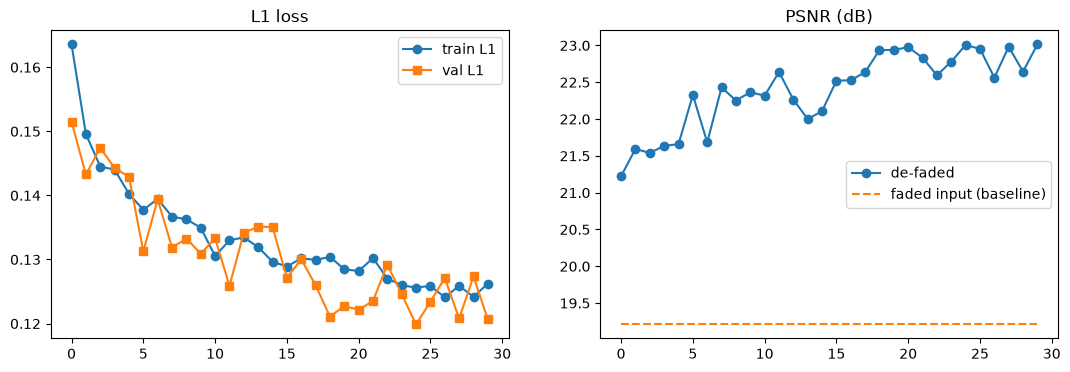

In [8]:
log = CKPT_DIR / 'color_log.csv'
if log.exists():
    df = pd.read_csv(log)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(df.epoch, df.g_l1, 'o-', label='train L1'); ax[0].plot(df.epoch, df.val_l1, 's-', label='val L1'); ax[0].legend(); ax[0].set_title('L1 loss')
    ax[1].plot(df.epoch, df.val_psnr, 'o-', label='de-faded'); ax[1].plot(df.epoch, df.baseline_psnr, '--', label='faded input (baseline)'); ax[1].legend(); ax[1].set_title('PSNR (dB)')
else:
    print('No color_log.csv yet - run scripts/train_color.py')

## 6. Restoration reports
Summary of `report.json` for every painting restored with `scripts/restore.py`.
Mandawa and personal hold-out results are in other folders and are not included.

In [9]:
reps = []
for p in sorted((ROOT / 'outputs/restored').glob('*/report.json')):
    r = json.loads(p.read_text()); r['painting'] = p.parent.name; reps.append(r)
if reps:
    display(pd.DataFrame(reps)[['painting', 'final_size', 'damaged_fraction', 'color_method', 'mean_confidence_in_infill', 'speculative_fraction_of_infill(conf<0.5)', 'total_s']])
else:
    print('No restored paintings yet.')

,painting,final_size,damaged_fraction,color_method,mean_confidence_in_infill,speculative_fraction_of_infill(conf<0.5),total_s
0,Warli-art-Dhatri-03-600x826,"[1652, 1200]",0.000365,pix2pix_adaptive,0.691368,0.0,11.66
